# COS711 Assignment 2: Solar Filament Segmentation

Initial Google Colab setup. This notebook downloads and inspects the official Kaggle competition files only.

## 1. Google colab check

In [21]:
#GPU test
import sys
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())

# Check NVIDIA GPU availability through PyTorch
try:
    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU count:", torch.cuda.device_count())
    else:
        print("No GPU allocated to this runtime.")

except ImportError:
    print("PyTorch is not installed.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU count: 1


## 2. Get data from shared drive

In [22]:
import os

# Kaggle mounts the competition data under /kaggle/input; on Colab it comes from the team Drive folder
ON_KAGGLE = os.path.exists("/kaggle/input")

if not ON_KAGGLE:
    from google.colab import drive
    drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
import glob, subprocess

if ON_KAGGLE:
    # Nothing to unzip: find the read-only competition folder that holds train/train_images
    found = glob.glob("/kaggle/input/**/train/train_images", recursive=True)
    assert found, "Competition data not found under /kaggle/input: add the competition with '+ Add Input'"
    DATA_DIR = os.path.dirname(os.path.dirname(found[0]))
else:
    # Members of the COS 711 shared drive see it under Shareddrives. Anyone the folder was shared with
    # can add a My Drive shortcut to it instead (Shared with me -> Organize -> Add shortcut).
    ZIP_NAME = "filament-segmentation-2026.zip"
    ZIP_DIRS = ["/content/drive/Shareddrives/COS 711/Assignment 2",
                "/content/drive/MyDrive/COS 711/Assignment 2",
                "/content/drive/MyDrive/Assignment 2"]
    ZIP = next((f"{d}/{ZIP_NAME}" for d in ZIP_DIRS if os.path.exists(f"{d}/{ZIP_NAME}")), None)
    assert ZIP, f"{ZIP_NAME} not found in any of {ZIP_DIRS}"
    # -n: skip files that already exist, so rerunning does not stop at a "replace?" prompt
    subprocess.run(["unzip", "-q", "-n", ZIP, "-d", "/content/data"], check=True)
    DATA_DIR = "/content/data/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
print("data:", DATA_DIR)

replace /content/data/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20110120105534Ch.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

## 3. Inspect dataset file names

In [24]:
from pathlib import Path

path = os.path.dirname(DATA_DIR)
data_root = Path(path)
for item in sorted(data_root.rglob('*')):
    if item.is_file():
        print(item.relative_to(data_root))

MAGFiLO_1.0_Kaggle_2026/test/test_images/20110120105534Ch.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110130110334Ch.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110214175414Mh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110329082654Uh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110408083214Th.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110424064534Lh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110429120534Ch.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110529063154Uh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110531070514Th.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110603123034Ch.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110706164014Mh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110811121534Ch.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110819131834Ch.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110827141254Bh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20110912142254Bh.jpeg
MAGFiLO_1.0_Kaggle_2026/test/test_images/20111015063134

## Data Preprocessing

The following steps are used:
1. Parse and group: load COCO Json and decode polygons
2. Split into train and validation tests 85/15
3. Convert to working resolution
4. Normalisation, 1st-99th percentiles are cliped and all data is scaled to [0, 1]
5. Build targets per annotated image

In [ ]:
!pip -q install pycocotools opencv-python-headless

In [25]:
import json, re, math, shutil
import numpy as np, pandas as pd, cv2
from pycocotools import mask as mu
from tqdm.auto import tqdm
from joblib import Parallel, delayed

DATA = Path(DATA_DIR)
TRAIN_IMG = DATA / "train/train_images"
ANN_JSON = next((DATA / "train").glob("*.json"))
# Kaggle: /kaggle/working is saved output (~20 GB), so the cache goes in the session's temporary space
CACHE = Path("/kaggle/temp/cache" if ON_KAGGLE else "/content/cache")
CACHE.mkdir(parents=True, exist_ok=True)
print(f"cache: {CACHE}, {shutil.disk_usage(CACHE).free / 2**30:.0f} GB free (the scale 1.0 cache needs about 45 GB)")

### Step 1

In [26]:
coco = json.load(open(ANN_JSON))
FNAME_RE = re.compile(r"^(\d{14})([A-Za-z]{2})")

imgs = pd.DataFrame(coco["images"])
imgs["image_id"] = imgs["id"].astype(str)
imgs["stem"] = imgs.file_name.map(lambda s: Path(s).stem)

m = imgs.stem.str.extract(FNAME_RE)
assert m.notna().all().all(), "Some file names do not match the expected pattern."

imgs["ts"], imgs["inst"] = m[0], m[1]
imgs["obs"] = imgs.ts + "_" + imgs.inst
imgs["annotator"] = imgs.image_id.str.split("-").str[0]
imgs["date"] = pd.to_datetime(imgs.ts, format="%Y%m%d%H%M%S")

on_disk = {p.stem: p for p in TRAIN_IMG.iterdir()}
imgs["path"] = imgs.stem.map(on_disk)
assert imgs.path.notna().all(), imgs[imgs.path.isna()].file_name.head()

# Merge all 4 categories into one class
ann_by_img = {}
for a in coco["annotations"]:
    ann_by_img.setdefault(a["image_id"], []).append(a)

missing = set(ann_by_img) - set(imgs.image_id)
print("Annotation image_ids no in images:", len(missing), missing)
print(pd.Series([a["category_id"] for a in coco["annotations"]]).value_counts())

obs = (imgs.groupby("obs")
       .agg(ts=("ts", "first"), inst=("inst", "first"), date=("date", "first"),
            stem=("stem", "first"), path=("path", "first"),
            n_sets=("image_id", "nunique")).reset_index())

print(len(imgs), "annotated image sets ->", len(obs), "observations")
print(obs.inst.value_counts())

Annotation image_ids no in images: 0 set()
3    3074
2    2590
1    2535
Name: count, dtype: int64
1154 annotated image sets -> 707 observations
inst
Lh    127
Ch    125
Mh    125
Bh    118
Th    110
Uh    102
Name: count, dtype: int64


#### Annotation cleaning

In [27]:
from skimage.measure import label as sk_label

def clean_annotations(anns, H=2048, W=2048, min_area=20, min_pts=3):
    """Drop degenerate/duplicate polygons. Returns cleaned list"""
    keep, seen = [], set()
    rep = dict(no_poly=0, too_few_pts=0, tiny=0, duplicate=0, ok=0)
    for a in anns:
        polys = [p for p in a.get("segmentation", []) if len(p) >= 2 * min_pts]
        if not polys:
            rep["no_poly" if not a.get("segmentation") else "too_few_pts"] += 1
            continue
        # clip coordinates to the image
        polys = [np.clip(np.asarray(p, float).reshape(-1, 2), 0, [W - 1, H - 1]).ravel().tolist()
                 for p in polys]
        rle = mu.merge(mu.frPyObjects(polys, H, W))
        area = float(mu.area(rle))
        if area < min_area:
            rep["tiny"] += 1
            continue
        key = (a["image_id"], round(area), tuple(mu.toBbox(rle).round().astype(int)))
        if key in seen:
            rep["duplicate"] += 1
            continue
        seen.add(key)
        a = {**a, "segmentation": polys, "area": area}
        keep.append(a)
        rep["ok"] += 1
    return keep, rep

coco["annotations"], rep = clean_annotations(coco["annotations"])
print(rep)

{'no_poly': 0, 'too_few_pts': 0, 'tiny': 1, 'duplicate': 0, 'ok': 8198}


### Step 2: Split

In [28]:
BLOCK_DAYS, VAL_SPLIT, SEED = 7, 0.15, 1

obs["block"] = (obs.date - obs.date.min()).dt.days // BLOCK_DAYS

def pick_val_blocks(obs, val_frac, seed=SEED):
    rng = np.random.default_rng(seed)
    total = obs.inst.value_counts()
    target = total * val_frac

    block = (obs.groupby(["block", "inst"]).size().unstack(fill_value=0)
              .reindex(columns=total.index, fill_value=0))
    cur, chosen = pd.Series(0.0, index=total.index), []

    for b in rng.permutation(block.index.values):
        new = cur + block.loc[b]
        if (new > target * 1.5 + 2).any():
            continue

        chosen.append(b)
        cur = new

        if (cur >= 0.9 * target).all() or cur.sum() >= target.sum():
            break

    return chosen

val_blocks = pick_val_blocks(obs, VAL_SPLIT)
obs["split"] = np.where(obs.block.isin(val_blocks), "val", "train")
print(pd.crosstab(obs.inst, obs.split, margins=True))

#Test and train dates test
test_ts = [re.match(FNAME_RE, p.stem).group(1) for p in (DATA/"test/test_images").glob("*.jp*g")]
test_dates = pd.to_datetime(pd.Series(test_ts), format="%Y%m%d%H%M%S")
print("train:", obs.date.min(), "->", obs.date.max(), " test:", test_dates.min(), "->", test_dates.max())


split  train  val  All
inst                  
Bh        98   20  118
Ch       107   18  125
Lh       109   18  127
Mh       103   22  125
Th        97   13  110
Uh        86   16  102
All      600  107  707
train: 2011-01-09 10:47:34 -> 2022-08-03 07:47:52  test: 2011-01-20 10:55:34 -> 2022-07-28 18:53:52


### Step 3: Verify resolution and downsample

In [29]:
def raster_crop(a, scale, h, w, pad=2):
    "Raterise one polygon into a bbox crop"
    polys = [np.asarray(p, float).reshape(-1, 2) * scale for p in a["segmentation"]]
    all_points = np.concatenate(polys)

    x0 = max(int(np.floor(all_points[:, 0].min())) - pad, 0)
    y0 = max(int(np.floor(all_points[:, 1].min())) - pad, 0)

    x1 = min(int(np.ceil(all_points[:, 0].max())) + pad + 1, w)
    y1 = min(int(np.ceil(all_points[:, 1].max())) + pad + 1, h)

    if x1 <= x0 or y1 <= y0:
        return None

    seg = [(p - [x0, y0]).ravel().tolist() for p in polys]
    mask = mu.decode(mu.merge(mu.frPyObjects(seg, y1 - y0, x1 - x0)))
    return np.ascontiguousarray(mask), x0, y0, x1, y1

def spine_points(a):
    sp = np.asarray(a.get("spine") or [], float).ravel()
    return sp[: sp.size // 2 * 2].reshape(-1, 2)

rows = []
for a in tqdm(coco["annotations"]):
    r = raster_crop(a, 1.0, 2048, 2048)

    if r is None: continue

    m = r[0]
    d = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    sp = spine_points(a)
    L = np.linalg.norm(np.diff(sp, axis=0), axis=1).sum() if len(sp) > 1 else np.nan

    rows.append(dict(area=m.sum(), spine_len=L, mean_w=m.sum() / L if L > 0 else np.nan, max_w=2*d.max()))

geo = pd.DataFrame(rows)
print("Geometric stats for", len(geo), "annotations")
print(geo.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(1))
print("Fraction with mean width < 4 px:", (geo.mean_w < 4).mean().round(3))
print("Fraction with max width < 4 px:", (geo.max_w < 4).mean().round(3))

  0%|          | 0/8198 [00:00<?, ?it/s]

Geometric stats for 8198 annotations
          area  spine_len  mean_w   max_w
count   8198.0     8198.0  8198.0  8198.0
mean    2120.1      147.4    12.7    18.2
std     2741.8      118.9     6.8     9.8
min       60.0       12.1     0.7     4.0
25%      670.0       70.6     8.3    11.6
50%     1228.5      111.3    11.1    16.0
75%     2439.0      182.5    15.2    22.0
90%     4684.9      285.2    21.0    30.4
95%     6947.7      386.9    25.5    37.2
99%    13703.7      627.6    37.4    52.7
max    37739.0     1105.0    70.2    93.1
Fraction with mean width < 4 px: 0.004
Fraction with max width < 4 px: 0.0


### Step 4: Normalisation

In [30]:
DISK_MARGIN = 1.01

def circle_mask(h, w, cx, cy, r):
    "Create a circular mask of radius r at (cx, cy) in an image of size h x w"
    yy, xx = np.ogrid[:h, :w]
    return (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2

def fit_disk(gray):
    "Otsu on a downsampled image to find largest blob and fit a circle on its contour"
    h, w = gray.shape
    s = cv2.GaussianBlur(cv2.resize(gray, (512, 512), interpolation=cv2.INTER_AREA), (0,0), 2)

    t, _ = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n, lab, stats, _ = cv2.connectedComponentsWithStats((s > t).astype(np.uint8))

    if n < 2: return None

    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    cnts, _ = cv2.findContours((lab == k).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    points = max(cnts, key=cv2.contourArea).reshape(-1, 2).astype(float)

    A = np.c_[2 * points, np.ones(len(points))]
    (cx, cy, c), *_ = np.linalg.lstsq(A, (points ** 2).sum(1), rcond=None)
    r = math.sqrt(c + cx ** 2 + cy ** 2)

    rms = np.sqrt(np.mean((np.hypot(points[:, 0]-cx, points[:,1]-cy) -r) ** 2)) / r
    touches_border = (points.min() <= 1) or (points.max() >= 510)

    # Cannot fit
    if not(0.2 * 512 < r < 0.7 * 512) or rms > 0.03: return None

    # return dict(otsu=t, n_blobs=n-1, blob_area_frac=blob.mean(), r=r, r_frac=r/512,
    #             rms=rms, touches_border=touches_border, cx=cx, cy=cy), blob

    return cx * w / 512, cy * h / 512, r * w / 512

# bad = obs_meta[~obs_meta.disk_ok].obs
# rows = []
# for o in bad:
#     path = obs.set_index("obs").path[o]
#     gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
#     d, blob = fit_disk(gray)
#     d["obs"] = o
#     rows.append(d)
# print(pd.DataFrame(rows).round(3))

In [31]:
def normalise(gray, disk):
    lo, hi = np.percentile(gray[disk], [1,99])
    x = np.clip((gray.astype(np.float32) - lo) / max(hi - lo, 1e-6), 0, 1)
    x[~disk] = 0
    return (x * 255 + 0.5).astype(np.uint8), lo, hi

### Step 5: Build targets

In [32]:
def build_targets(anns, h, w, scale, spine_r=1, contact_r=1):
    inst = np.zeros((h, w), np.uint16)
    dist = np.zeros((h, w), np.float32)
    spine = np.zeros((h, w), np.uint8)
    centers = []

    for k, a in enumerate(sorted(anns, key=lambda a: -a["area"]), 1):
        r = raster_crop(a, scale, h, w)

        if r is None: continue

        m, x0, y0, x1, y1 = r
        mb = m.astype(bool)

        if not mb.any(): continue

        inst[y0:y1, x0:x1][mb] = k
        d = cv2.distanceTransform(m, cv2.DIST_L2, 5)
        d /= max(d.max(), 1e-6)
        dist[y0:y1, x0:x1][mb] = d[mb]
        ys, xs = np.nonzero(mb)

        centers.append([round(float(xs.mean() + x0), 1), round(float(ys.mean() + y0), 1)])
        sp = spine_points(a) * scale

        if len(sp) > 1:
            cv2.polylines(spine, [np.round(sp).astype(np.int32).reshape(-1, 1, 2)], False, 1, 1)

    if spine_r > 0:
        spine = cv2.dilate(spine, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*spine_r+1,)*2))

    # boundary and contact
    lab = inst.astype(np.float32)
    fg = lab > 0
    k3 = np.ones((3, 3), np.uint8)
    boundary = fg & ((cv2.dilate(lab, k3) != lab) | (cv2.erode(lab, k3) != lab))
    kc = np.ones((2*contact_r+1,)*2, np.uint8)

    mx = cv2.dilate(lab, kc)
    mn = cv2.erode(np.where(fg, lab, np.float32(1e9)), kc)
    contact = (mx > 0) & (mn < 1e9) & (mx != mn)
    contact = cv2.dilate(contact.astype(np.uint8), k3).astype(bool)

    boundary |= contact

    target = np.stack([fg, boundary, contact, np.round(dist * 255), spine]).astype(np.uint8)
    return inst, target, centers


In [33]:
def process_obs(obs_key, path, inst_name, set_ids, ann_by_img, scale, out):
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    H0, W0 = gray.shape
    H, W = int(round(H0 * scale)), int(round(W0 * scale))

    p = fit_disk(gray)
    disk_ok = p is not None

    cx, cy, r = p if disk_ok else (W0 / 2, H0 /2, min(H0, W0) / 2)

    disk0 = circle_mask(H0, W0, cx, cy, r * DISK_MARGIN)
    raw = gray[disk0].astype(np.float32)
    img8, lo, hi = normalise(gray, disk0)

    if scale != 1:
        img8 = cv2.resize(img8, (W, H), interpolation=cv2.INTER_AREA)

    cx, cy, r = cx * scale, cy * scale, r * scale
    disk = circle_mask(H, W, cx, cy, r * DISK_MARGIN)
    img8[~disk] = 0

    soft = np.zeros((H, W), np.float32)
    set_rows = []
    for iid in set_ids:
        anns = ann_by_img.get(iid, [])
        inst, tgt, centers = build_targets(anns, H, W, scale)
        np.save(out / "tgt"/ f"{iid}.npy", tgt)
        np.save(out / "inst" / f"{iid}.npy", inst)
        soft += tgt[0]

        set_rows.append(dict(image_id=iid, obs=obs_key, n_inst=len(centers), centers=json.dumps(centers)))

    soft = (soft / max(len(set_ids), 1) * 255 + 0.5).astype(np.uint8)
    np.save(out / "obs" / f"{obs_key}.npy", np.stack([img8, disk.astype(np.uint8), soft]))

    nrm = img8[disk].astype(np.float32) / 255
    obs_row = dict(obs=obs_key, inst=inst_name, cx=cx, cy=cy, r=r, disk_ok=disk_ok, 
                   raw_mean=raw.mean(), raw_std=raw.std(), raw_p01=lo, raw_p99=hi, 
                   norm_mean=nrm.mean(), norm_std=nrm.std())
    return obs_row, set_rows

In [34]:
def build_cache(scale=1.0):
    out = CACHE / f"scale{scale}"

    for d in ("obs", "tgt", "inst"): (out / d).mkdir(parents=True, exist_ok=True)
    sets = imgs.groupby("obs").image_id.apply(list)
    jobs = (delayed(process_obs)(r.obs, r.path, r.inst, sets[r.obs], ann_by_img, scale, out)
            for r in obs.itertuples())

    res = list(tqdm(Parallel(n_jobs=-1, return_as="generator")(jobs), total=len(obs)))
    obs_meta = pd.DataFrame([r[0] for r in res]).merge(obs[["obs", "date", "split", "n_sets"]], on="obs")
    set_meta = pd.DataFrame([s for r in res for s in r[1]]).merge(obs_meta[["obs", "inst", "split"]], on="obs")
    obs_meta.to_csv(out / "obs_meta.csv", index=False)
    set_meta.to_csv(out / "set_meta.csv", index=False)
    return obs_meta, set_meta

obs_meta, set_meta = build_cache(scale=1.0)
print("failed disk fits:", (~obs_meta.disk_ok).sum(), "of", len(obs_meta))
print(obs_meta.groupby("inst")[["raw_mean","raw_std","raw_p01","raw_p99","norm_mean","norm_std"]]
      .agg(["mean","std"]).round(2).T)

  0%|          | 0/707 [00:00<?, ?it/s]

failed disk fits: 11 of 707
inst                    Bh          Ch          Lh          Mh          Th  \
raw_mean  mean  122.129997  123.639999  122.040001  122.830002  118.769997   
          std     4.660000    3.090000    2.380000    2.750000    5.150000   
raw_std   mean   23.790001   23.340000   23.139999   22.950001   23.280001   
          std     3.520000    0.980000    1.050000    1.150000    1.860000   
raw_p01   mean   41.280000   38.390000   40.860000   35.550000   51.330000   
          std    12.060000    8.090000    5.930000    8.850000    8.890000   
raw_p99   mean  160.690000  162.780000  161.970000  161.210000  160.630000   
          std     7.290000    6.730000    6.480000    5.240000    5.420000   
norm_mean mean    0.680000    0.680000    0.670000    0.690000    0.610000   
          std     0.040000    0.040000    0.040000    0.050000    0.050000   
norm_std  mean    0.190000    0.180000    0.180000    0.170000    0.200000   
          std     0.030000    0.0100

In [35]:
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826 + 1e-6
    return (s - med) / mad

for c in ["raw_mean", "raw_std", "norm_mean", "norm_std"]:
    obs_meta[c + "_z"] = obs_meta.groupby("inst")[c].transform(robust_z)

obs_meta["qc_flag"] = (~obs_meta.disk_ok) | (obs_meta[[c for c in obs_meta if c.endswith("_z")]].abs() > 4).any(axis=1)
print(obs_meta.groupby(["inst", "split"]).qc_flag.agg(["sum", "count"]))

            sum  count
inst split            
Bh   train   15     98
     val      3     20
Ch   train   21    107
     val      3     18
Lh   train    5    109
     val      1     18
Mh   train   11    103
     val      4     22
Th   train   12     97
     val      3     13
Uh   train    0     86
     val      2     16


In [36]:
print(obs_meta[~obs_meta.disk_ok].inst.value_counts())

inst
Bh    11
Name: count, dtype: int64


### Setup dataset for the U-net

In [37]:
import torch
from torch.utils.data import Dataset, DataLoader

class FilamentDS(Dataset):
    def __init__(self, set_meta, obs_meta, cache, crop=512, train=True, pos_prob=0.8, limb_w=0.3):
        self.m = set_meta.merge(obs_meta[["obs", "cx", "cy", "r"]], on="obs").reset_index(drop=True)
        self.c, self.crop, self.train, self.pos_prob, self.limb_w = Path(cache), crop, train, pos_prob, limb_w

    def __len__(self): return len(self.m)

    def _origin(self, r, H, W, rng):
        cs = self.crop
        centers = json.loads(r.centers)
        if centers and rng.random() < self.pos_prob:
            cx, cy = centers[rng.integers(len(centers))]
            x0 = int(cx - cs / 2 + rng.integers(-cs // 4, cs // 4 + 1))
            y0 = int(cy - cs / 2 + rng.integers(-cs // 4, cs // 4 + 1))
            
        else:
            lx, ly = int(np.clip(r.cx - r.r, 0, W - cs)), int(np.clip(r.cy - r.r, 0, H - cs))
            hx, hy = int(np.clip(r.cx + r.r - cs, lx, W - cs)), int(np.clip(r.cy + r.r - cs, ly, H-cs))
            x0, y0 = rng.integers(lx, hx + 1), rng.integers(ly, hy + 1)

        return int(np.clip(y0, 0, H - cs)), int(np.clip(x0, 0, W - cs))

    def __getitem__(self, i):
        r = self.m.iloc[i]
        # (3,H,W): img, disk, soft
        obs = np.load(self.c / "obs" / f"{r.obs}.npy", mmap_mode="r")

        # (5,H,W)
        tgt = np.load(self.c / "tgt" / f"{r.image_id}.npy", mmap_mode="r")
        H, W = tgt.shape[1:]
        rng = np.random.default_rng()

        if self.train:
            y0, x0 = self._origin(r, H, W, rng)
            h = w = self.crop

        else:
            y0 = x0 = 0
            h, w = H, W

        o = np.array(obs[:, y0:y0+h, x0:x0+w])
        t = np.array(tgt[:, y0:y0+h, x0:x0+w])

        yy, xx = np.mgrid[y0:y0+h, x0:x0+w]
        rn = np.hypot(xx - r.cx, yy - r.cy) / r.r
        wt = np.interp(rn, [0.9, 1.0], [1.0, self.limb_w]).astype(np.float32) * o[1]

        arrs = [o, t, wt[None]]

        if self.train:
            k, flip = rng.integers(4), rng.random() < 0.5
            arrs = [np.rot90(a, k, (1, 2)) for a in arrs]
            if flip: arrs = [a[:, :, ::-1] for a in arrs]

        o, t, wt = [np.ascontiguousarray(a) for a in arrs]

        tt = t.astype(np.float32)
        tt[3] /= 255.0

        return dict(image=torch.from_numpy(o[:1].astype(np.float32) / 255),
                    target=torch.from_numpy(tt),
                    soft_fg=torch.from_numpy(o[2:3].astype(np.float32) / 255),
                    weight=torch.from_numpy(wt)) 

In [38]:
cache = CACHE / "scale1.0"
train_ds = FilamentDS(set_meta[set_meta.split == "train"], obs_meta, cache, train=True)
val_ds   = FilamentDS(set_meta[set_meta.split == "val"],   obs_meta, cache, train=False)
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2, drop_last=True)
b = next(iter(train_dl)); print({k: v.shape for k, v in b.items()})


{'image': torch.Size([8, 1, 512, 512]), 'target': torch.Size([8, 5, 512, 512]), 'soft_fg': torch.Size([8, 1, 512, 512]), 'weight': torch.Size([8, 1, 512, 512])}


image torch.float32 min=0.000 max=1.000 mean=0.6852
target torch.float32 min=0.000 max=1.000 mean=0.0031
soft_fg torch.float32 min=0.000 max=1.000 mean=0.0079
weight torch.float32 min=0.000 max=1.000 mean=0.9274
per-channel target mean: tensor([0.0080, 0.0024, 0.0000, 0.0029, 0.0020])
frac of crops with any fg: 1.0


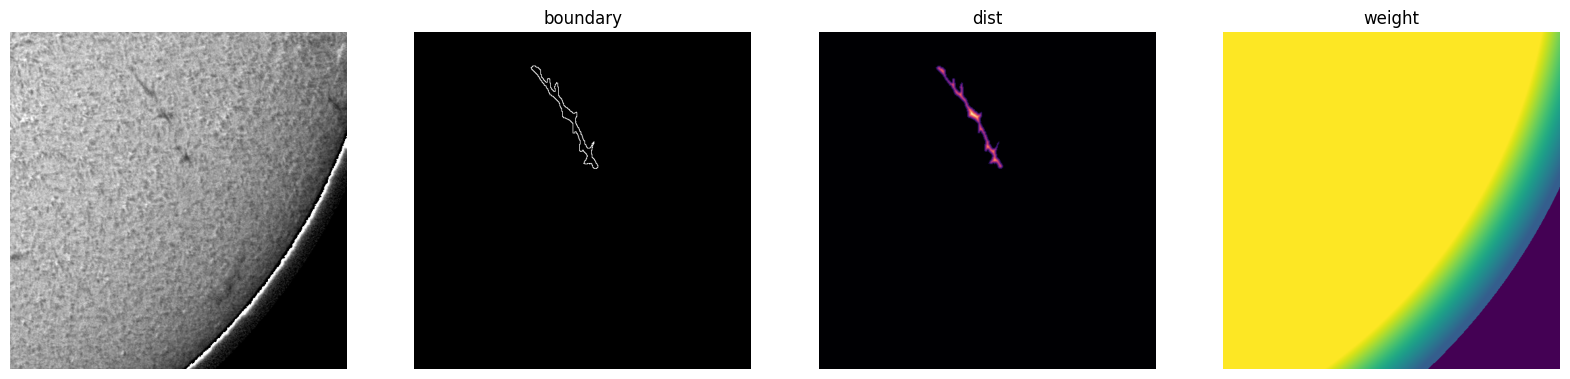

In [39]:
import matplotlib.pyplot as plt

b = next(iter(train_dl))
for k, v in b.items():
    print(k, v.dtype, f"min={v.min():.3f} max={v.max():.3f} mean={v.mean():.4f}")
print("per-channel target mean:", b["target"].mean((0, 2, 3)))
print("frac of crops with any fg:", (b["target"][:, 0].flatten(1).sum(1) > 0).float().mean().item())

i = 0
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(b["image"][i, 0], cmap="gray")
ax[1].imshow(b["target"][i, 1], cmap="gray"); ax[1].set_title("boundary")
ax[2].imshow(b["target"][i, 3], cmap="magma"); ax[2].set_title("dist")
ax[3].imshow(b["weight"][i, 0], cmap="viridis"); ax[3].set_title("weight")
for a in ax: a.axis("off")


### Metrics

In [40]:
import time

def dice_iou(pred, gt, eps=1e-9):
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = (pred & gt).sum(); s = pred.sum() + gt.sum(); u = (pred | gt).sum()
    if s == 0: return 1.0, 1.0                     # both empty
    return 2 * inter / (s + eps), inter / (u + eps)

def panoptic_quality(pred_inst, gt_inst, iou_thr=0.5):
    """PQ = SQ * RQ. IoU>0.5 guarantees unique matches"""
    P, G = pred_inst.max() + 1, gt_inst.max() + 1
    cont = np.bincount(gt_inst.ravel().astype(np.int64) * P + pred_inst.ravel(),
                       minlength=G * P).reshape(G, P)
    ga, pa = cont.sum(1), cont.sum(0)
    iou = cont / (ga[:, None] + pa[None, :] - cont + 1e-9)
    iou[0, :] = 0; iou[:, 0] = 0                   # ignore background
    gi, pi = np.nonzero(iou > iou_thr)
    tp = len(gi); ious = iou[gi, pi]
    n_gt, n_pr = len(np.unique(gt_inst)) - (0 in gt_inst), len(np.unique(pred_inst)) - (0 in pred_inst)
    fp, fn = n_pr - tp, n_gt - tp
    sq = ious.mean() if tp else 0.0
    rq = tp / (tp + 0.5 * fp + 0.5 * fn) if (tp + fp + fn) else 1.0
    return dict(PQ=sq * rq, SQ=sq, RQ=rq, TP=tp, FP=fp, FN=fn)

def split_merge(pred_inst, gt_inst, min_frac=0.1):
    """one-to-many: GT covered by >=2 preds; many-to-one: pred covering >=2 GTs.
    A link counts if the intersection is >= min_frac of the *smaller* object's area."""
    P, G = pred_inst.max() + 1, gt_inst.max() + 1
    cont = np.bincount(gt_inst.ravel().astype(np.int64) * P + pred_inst.ravel(),
                       minlength=G * P).reshape(G, P)[1:, 1:]
    if cont.size == 0: return dict(one_to_many=0, many_to_one=0, n_gt=G-1, n_pred=P-1)
    ga, pa = cont.sum(1), cont.sum(0)
    link = cont >= min_frac * np.minimum(ga[:, None], pa[None, :]).clip(1)
    link &= cont > 0
    return dict(one_to_many=int((link.sum(1) >= 2).sum()),
                many_to_one=int((link.sum(0) >= 2).sum()),
                n_gt=int((ga > 0).sum()), n_pred=int((pa > 0).sum()))